# Chapitre 8 - Exercices 8.1 à 8.6

Ce notebook traite les premiers exercices du chapitre 8, centrés sur les réseaux, la
détection des pannes et les horloges :

- **8.1** : pannes partielles à l'échelle d'un parc (calcul et simulation) ;
- **8.2** : relances, idempotence et durée de rétention des identifiants (raisonnement
  et mini-lab) ;
- **8.3** : choisir un délai d'expiration face à une queue lourde, seul ou à plusieurs
  observateurs (calcul) ;
- **8.4** : le détecteur phi accrual à la main (calcul et mini-lab) ;
- **8.5** : tampon de commutateur, perdre ou attendre (calcul et simulation) ;
- **8.6** : budget d'horloge, calcul NTP et serveur menteur (calcul).

In [1]:
import itertools
import math
import random
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network, Node

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## Exercice 8.1 : pannes partielles à l'échelle d'un parc

**Énoncé.** Un service tourne sur 2 000 serveurs. Chaque serveur subit une panne
matérielle définitive en moyenne tous les 4 ans (MTTF), et il est par ailleurs
**transitoirement** injoignable ou trop lent 0,05 % du temps, indépendamment des autres.
Une requête d'utilisateur est éclatée en 40 sous-requêtes vers 40 serveurs différents et
n'aboutit que si toutes répondent. Le service reçoit 5 000 requêtes par seconde.

1. Combien de pannes définitives attend-on par jour ? Quelle est la probabilité de passer
   une semaine sans aucune ?
2. Quelle proportion des requêtes rencontre au moins un serveur en faute transitoire ?
   Combien de requêtes par jour cela représente-t-il ?
3. Chaque sous-requête peut désormais être servie par l'une de 2 répliques (on choisit
   une réplique saine). Que deviennent ces chiffres ? Et avec 3 répliques ?

**Rappels.** Panne partielle, « un sur un million, c'est tous les jours », probabilité
d'au moins une faute $1-(1-p)^n$ (cours 1, section 1 ; section *Faults and Partial
Failures*) ; pannes de Poisson (chapitre 1).

**Solution.**

*1.* Le taux de pannes du parc vaut $\lambda = 2000 / (4 \times 365) \approx 1{,}37$ par
jour : plus d'une panne définitive par jour. Les pannes forment un processus de Poisson,
donc $P(\text{aucune en 7 jours}) = e^{-7\lambda} \approx e^{-9{,}6} \approx 7 \times 10^{-5}$ :
une semaine sans panne n'arrive pour ainsi dire jamais.

*2.* Avec $p = 5 \times 10^{-4}$ et $n = 40$ : $1 - (1-p)^{40} \approx 40p = 2{,}0\,\%$ des
requêtes. Par jour : $5000 \times 86\,400 \times 0{,}0198 \approx 8{,}6$ millions de requêtes.

*3.* Une sous-requête n'échoue plus que si ses $r$ répliques sont toutes en faute :
$p^r$. Avec $r = 2$ : $p^2 = 2{,}5 \times 10^{-7}$, d'où $1-(1-p^2)^{40} \approx 10^{-5}$,
soit environ 4 300 requêtes par jour ; avec $r = 3$, environ 2 par jour. La redondance
multiplie l'**exposant** (si les fautes sont indépendantes, ce qu'il faut toujours
vérifier, chapitre 1).

pannes définitives : 1.37/jour ; semaines sans panne simulées : 0.00000 (théorie 0.00007)


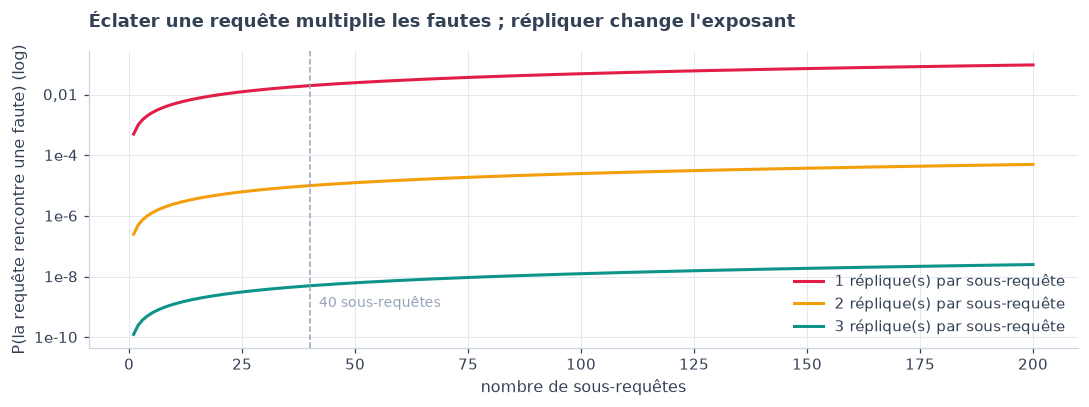

,P_formule,P_simulée,requêtes_par_jour
répliques,,,
1,1.9806e-02,1.9850e-02,8.5563e+06
2,1.0000e-05,1.2500e-05,4.3200e+03
3,5.0000e-09,0.0000e+00,2.1600e+00


In [2]:
lam = 2000 / (4 * 365)
p, n, debit = 5e-4, 40, 5000
rows = []
for r in (1, 2, 3):
    pr = 1 - (1 - p ** r) ** n
    panne = np.ones((400_000, n), bool)                    # Monte-Carlo : 400 000 requêtes
    for _ in range(r):                                     # une sous-requête échoue si ses r répliques sont en faute
        panne &= rng.random((400_000, n), dtype=np.float32) < p
    sim = np.mean(panne.any(axis=1))
    rows.append(dict(répliques=r, P_formule=pr, P_simulée=sim, requêtes_par_jour=pr * debit * 86_400))
R = pd.DataFrame(rows).set_index("répliques")
jours = rng.poisson(lam, 365 * 50)                         # 50 années simulées
print(f"pannes définitives : {lam:.2f}/jour ; semaines sans panne simulées : "
      f"{np.mean(jours[: (jours.size // 7) * 7].reshape(-1, 7).sum(axis=1) == 0):.5f} (théorie {math.exp(-7 * lam):.5f})")
fig, ax = plt.subplots(figsize=(10, 3.8))
fan = np.arange(1, 201)
for r, c in [(1, ROSE), (2, AMBER), (3, TEAL)]:
    ax.semilogy(fan, 1 - (1 - p ** r) ** fan, color=c, label=f"{r} réplique(s) par sous-requête")
ax.axvline(40, color=GRAY, ls="--", lw=1); ax.text(42, 1e-9, "40 sous-requêtes", fontsize=9, color=GRAY)
plain_log_axis(ax, "y")
ax.set_xlabel("nombre de sous-requêtes"); ax.set_ylabel("P(la requête rencontre une faute) (log)")
ax.set_title("Éclater une requête multiplie les fautes ; répliquer change l'exposant")
ax.legend()
plt.tight_layout(); plt.show()
R

La simulation confirme les formules pour 1 et 2 répliques (avec 3, l'événement est trop
rare pour 400 000 tirages : la simulation donne 0). La semaine sans panne est si rare que
même 50 années simulées n'en contiennent quasiment aucune.

> **À retenir.** À l'échelle d'un parc, les pannes définitives sont quotidiennes et une
> requête éclatée rencontre souvent une faute transitoire. La redondance des
> sous-requêtes ramène ce risque de quelques pourcents à quelques millionièmes.

## Exercice 8.2 : relances, idempotence et durée de rétention des identifiants

**Énoncé.** Un service de paiement reçoit des ordres « débiter 50 € ». Le client attend
la réponse 2 s, puis relance (au plus 3 relances).

1. Pour chacun des scénarios suivants, dire ce que voit le client et ce que devient le
   compte : (a) la requête se perd ; (b) le serveur tombe avant de traiter ; (c) la réponse
   se perd ; (d) le serveur est en pause 5 s puis traite et répond.
2. On ajoute un identifiant unique à chaque ordre ; le serveur mémorise les identifiants
   déjà traités pendant une durée de rétention $D$ puis les oublie. Pourquoi faut-il une
   rétention ? Quelle valeur minimale proposer ?
3. Mini-lab : simuler 3 000 ordres sur un réseau qui perd 5 % des messages et retarde
   parfois un message de 15 s ; mesurer les doubles débits selon $D$.

**Rappels.** Ce que l'émetteur ne peut pas savoir, relances et identifiants (cours 1,
section 2 ; section *Unreliable Networks*) ; délais arbitraires (*Network Faults in Practice*).

**Solution.**

*1.* Dans les quatre cas, le client voit la même chose : **pas de réponse en 2 s**. Il
relance. Le compte, lui : (a) n'est pas débité par la première requête, la relance le
débite une fois ; (b) idem si le serveur redémarre ; (c) **a été débité** par la première
requête, la relance le débite une **seconde** fois ; (d) **double débit** aussi : la
requête initiale est traitée après la relance. Sans identifiant, (c) et (d) sont des
doubles débits.

*2.* Le serveur ne peut pas garder les identifiants indéfiniment (mémoire). Mais s'il
oublie un identifiant alors qu'une copie de l'ordre circule encore (relance tardive ou
message retardé dans le réseau), cette copie sera exécutée une seconde fois. La
rétention doit couvrir la **fenêtre** pendant laquelle une copie peut arriver :
$D \geq$ (durée totale des relances) + (délai réseau maximal plausible). Ici, 3 relances
espacées de 2 s font 6 s, plus 15 s de retard possible : $D \geq 21$ s, et l'on prend de la
marge, car aucun délai réseau n'est vraiment borné.

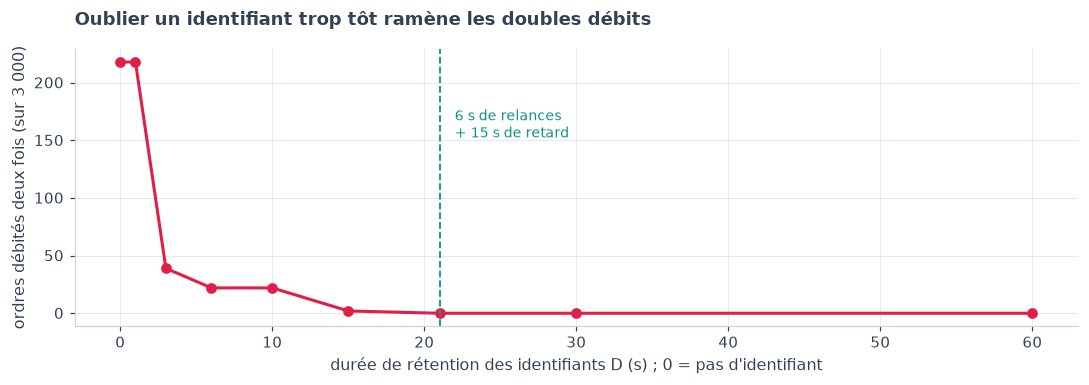

rétention_s,0,1,3,6,10,15,21,30,60
doubles_débits,218,218,39,22,22,2,0,0,0


In [3]:
class Banque(Node):
    def __init__(self, name, retention):
        super().__init__(name)
        self.retention, self.vus, self.debits = retention, {}, {}

    def on_message(self, src, msg):
        _, oid = msg
        for k in [k for k, t in self.vus.items() if self.now - t > self.retention]:
            del self.vus[k]                                  # oubli des vieux identifiants
        if oid not in self.vus:
            self.debits[oid] = self.debits.get(oid, 0) + 1
        self.vus[oid] = self.vus.get(oid, self.now)
        self.send(src, ("ok", oid))


class Payeur(Node):
    def __init__(self, name, n):
        super().__init__(name)
        self.n, self.ok = n, set()

    def on_start(self):
        for oid in range(self.n):
            self.set_timer(oid * 0.2, self.essai, oid, 0)

    def essai(self, oid, k):
        if oid in self.ok or k > 3:
            return
        self.send("banque", ("débiter 50", oid))
        self.set_timer(2.0, self.essai, oid, k + 1)

    def on_message(self, src, msg):
        self.ok.add(msg[1])


def latence(rng_, src, dst):
    return rng_.uniform(0.05, 0.6) + (15.0 if rng_.random() < 0.01 else 0.0)

rows = []
for D in [0, 1, 3, 6, 10, 15, 21, 30, 60]:
    net = Network(seed=5, latency=latence, drop=0.05)
    b = net.add(Banque("banque", D if D else -1))
    net.add(Payeur("client", 3000))
    net.run()
    doubles = sum(v >= 2 for v in b.debits.values())
    rows.append(dict(rétention_s=D, doubles_débits=doubles, mémoire_max=None))
Dd = pd.DataFrame(rows).drop(columns="mémoire_max")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(Dd.rétention_s, Dd.doubles_débits, "o-", color=ROSE)
ax.axvline(21, color=TEAL, ls="--", lw=1.2); ax.text(22, Dd.doubles_débits.max() * 0.7, "6 s de relances\n+ 15 s de retard", color=TEAL, fontsize=9)
ax.set_xlabel("durée de rétention des identifiants D (s) ; 0 = pas d'identifiant")
ax.set_ylabel("ordres débités deux fois (sur 3 000)")
ax.set_title("Oublier un identifiant trop tôt ramène les doubles débits")
plt.tight_layout(); plt.show()
Dd.set_index("rétention_s").T

Sans identifiant, plus de deux cents ordres sont débités deux fois. Une rétention
courte supprime les doublons dus aux relances rapprochées, mais pas ceux dus aux
messages retardés de 15 s ; à partir d'une rétention qui couvre relances et retard, il
n'en reste plus.

> **À retenir.** Une relance n'est sûre que si l'opération est idempotente. Avec des
> identifiants de requête, la durée de rétention doit couvrir la fenêtre des relances
> **et** le pire retard réseau plausible.